# Grad-CAM for the mask runs: where does the CT + mask model look?

The same as grad_cam.ipynb, but for the runs trained with the box mask as a 2nd input channel
(`train_no_fold.py --mask`). The heatmap is still drawn over the CT, and the mask's outline is drawn
in white on every panel, so you can see whether the heat follows the nodule or just fills the box.

Reads:  runs/cls_no_fold_mask/<run>/best.pt, config.json, <split>_preds.csv
        the patches and masks on the external drive (plug in Expansion first)

This is not a metric it is just a visualisation

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent if Path.cwd().name == "Model" else Path.cwd()
sys.path.insert(0, str(PROJECT / "Model"))                 # net.py
sys.path.insert(0, str(PROJECT / "Model" / "no_folds"))    # the no-folds Dataset
from net import NoduleNet3D
from dataset_patches_no_fold import NoduleDataset, CROP

RUNS_DIR = PROJECT / "runs" / "cls_no_fold_mask"
RUNS = {"hard": "hard_seed1", "soft": "soft_seed1"}   # one model A and one model B, compared side by side
SPLIT = "val"       # look at val freely; only use "test" for a final figure, never to change the model

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("device", device)

device mps


## 1. Load the trained models

Mask runs have `"mask": true` in their config.json and a 2-channel first layer (`in_channels=2`).

In [2]:
def load_model(run):
    cfg = json.loads((RUNS_DIR / run / "config.json").read_text())
    if cfg["crop"] != CROP:
        raise ValueError(f"{run} was trained on {cfg['crop']} mm crops but the Dataset cuts {CROP} mm")
    if not cfg.get("mask", False):
        raise ValueError(f"{run} was trained without the mask: use grad_cam.ipynb for it")
    model = NoduleNet3D(in_channels=2).to(device)
    model.load_state_dict(torch.load(RUNS_DIR / run / "best.pt", map_location=device))
    return model.eval()        # eval: dropout off, BatchNorm uses its saved averages

models = {kind: load_model(run) for kind, run in RUNS.items()}

## 2. Load the cubes and each model's predictions

`mask=True`: each x is (2, CROP, CROP, CROP), channel 0 the CT, channel 1 the box mask.
`err` = predicted rating − true (median) rating, so −2 means the model said 2 lower than the readers.

In [3]:
data = NoduleDataset(SPLIT, "hard", mask=True)
df = data.df[["nodule_key", "ratings", "hard", "spread", "diameter_mm"]].copy()

P_COLS = [f"p{k}" for k in range(1, 6)]
for kind, run in RUNS.items():
    preds = pd.read_csv(RUNS_DIR / run / f"{SPLIT}_preds.csv").set_index("nodule_key")
    probs = preds.loc[df["nodule_key"], P_COLS].to_numpy()
    df[f"pred_{kind}"] = probs.argmax(1) + 1          # index 0..4 -> rating 1..5
    df[f"err_{kind}"] = df[f"pred_{kind}"] - df["hard"]

# check: the loaded model reproduces the saved predictions (catches a wrong run, crop, checkpoint or mask)
for kind, model in models.items():
    preds = pd.read_csv(RUNS_DIR / RUNS[kind] / f"{SPLIT}_preds.csv").set_index("nodule_key")
    x = torch.stack([data[i][0] for i in range(5)]).to(device)
    with torch.no_grad():
        now = torch.softmax(model(x), 1).cpu().numpy()
    saved = preds.loc[df["nodule_key"][:5], P_COLS].to_numpy()
    print(f"{kind}: largest difference from the saved probabilities {np.abs(now - saved).max():.5f} (should be ~0)")

print(f"{len(df)} {SPLIT} nodules")
df.head()

hard: largest difference from the saved probabilities 0.00000 (should be ~0)
soft: largest difference from the saved probabilities 0.00000 (should be ~0)
290 val nodules


,nodule_key,ratings,hard,spread,diameter_mm,pred_hard,err_hard,pred_soft,err_soft
0,LIDC-IDRI-0006_920957_02,3;4;3;2,3,2,8.281250,3,0,3,0
1,LIDC-IDRI-0006_920957_03,3;3,3,0,6.250000,3,0,2,-1
2,LIDC-IDRI-0012_457842_01,2;3;3;2,3,1,6.308598,3,0,3,0
3,LIDC-IDRI-0012_457842_02,4;3;5;2,4,3,11.875008,4,0,3,-1
4,LIDC-IDRI-0012_457842_03,3;3;3;2,3,1,7.050786,3,0,3,0


## 3. Grad-CAM

1. Run the cube through the model, keeping the chosen layer's output (the activations: where each channel fires).
2. Backpropagate the score to that layer (the gradients: how much each channel matters for the score).
3. Weight per channel = its average gradient. Heatmap = weighted sum of the channels, negatives set to 0.
4. Stretch the heatmap up to the cube's size and scale it to 0..1.

The score is log P(rating in `classes`). With a 40 mm crop, `model.features[4]` (third block) is
10×10×10, so 4 mm per cell; `model.features[6]` (last block) is 5×5×5, so 8 mm per cell.
The layers after the first one are the same as the CT-only model, so nothing here changes for the mask.

In [4]:
def grad_cam(model, x, layer, classes):
    """x: one cube (1, 2, CROP, CROP, CROP). classes: ratings to explain, e.g. [4, 5] for 'suspicious'."""
    store = {}
    def keep(module, inp, out):
        store["act"] = out
        out.register_hook(lambda g: store.update(grad=g))   # tensor hook: safe with ReLU(inplace=True)
    h = layer.register_forward_hook(keep)
    model.eval()
    out = model(x)
    idx = [c - 1 for c in classes]
    score = torch.logsumexp(out[0, idx], 0) - torch.logsumexp(out[0], 0)   # log P(those ratings)
    model.zero_grad()
    score.backward()
    h.remove()
    w = store["grad"].mean(dim=(2, 3, 4), keepdim=True)        # how much each channel mattered
    cam = F.relu((w * store["act"]).sum(1, keepdim=True)).detach().cpu()
    cam = F.interpolate(cam, size=x.shape[2:], mode="trilinear", align_corners=False)[0, 0]
    return (cam / (cam.max() + 1e-8)).numpy()

## 4. Plot one nodule

Rows: the three centre slices through the cube. Columns: the CT, then each model's heatmap on top.
The white line is the edge of the box mask.
By default each model's map explains **its own predicted rating** ("why did you say this?").
Pass `classes=[4, 5]` instead to ask both models the same question ("what looks suspicious to you?").

**What to look for:** heat that fills the whole box evenly suggests the model is mostly using the
box's size; heat on particular parts of the nodule (its edge, spikes, a dense core) suggests it is
using the nodule's shape or texture.

In [5]:
c = CROP // 2
VIEWS = {"axial": lambda v: v[c], "coronal": lambda v: v[:, c], "sagittal": lambda v: v[:, :, c]}

def show(i, classes=None, layer=4):
    row = df.iloc[i]
    x = data[i][0].unsqueeze(0).to(device)
    ct = x[0, 0].cpu().numpy()
    mask = x[0, 1].cpu().numpy()
    cams = {}
    for kind, model in models.items():
        cls = classes or [int(row[f"pred_{kind}"])]
        cams[kind] = (grad_cam(model, x, model.features[layer], cls), cls)

    fig, axes = plt.subplots(3, 1 + len(cams), figsize=(3 * (1 + len(cams)), 9))
    for r, (view, cut) in enumerate(VIEWS.items()):
        axes[r, 0].imshow(cut(ct), cmap="gray", vmin=-1, vmax=1)
        axes[r, 0].set_ylabel(view)
        for col, (kind, (cam, cls)) in enumerate(cams.items(), start=1):
            axes[r, col].imshow(cut(ct), cmap="gray", vmin=-1, vmax=1)
            axes[r, col].imshow(cut(cam), cmap="jet", alpha=0.4, vmin=0, vmax=1)
            if r == 0:
                axes[r, col].set_title(f"{kind}: predicted {row[f'pred_{kind}']}\nexplaining rating(s) {cls}")
        if cut(mask).any():           # the box's edge on every panel of this row
            for ax in axes[r]:
                ax.contour(cut(mask), levels=[0.5], colors="w", linewidths=0.8)
    axes[0, 0].set_title("CT (white = box mask)")
    for ax in axes.flat:
        ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f"{row['nodule_key']}   readers {row['ratings']} -> true {row['hard']}   "
                 f"{row['diameter_mm']:.0f} mm", y=1.0)
    fig.tight_layout()
    plt.show()

def show_key(key, classes=None, layer=4):
    """The same plot, picked by nodule_key instead of row number."""
    show(int(np.flatnonzero(df["nodule_key"] == key)[0]), classes, layer)

## 5. The worst mistakes

Nodules where a model's rating is off by 2 or more.

Sometimes the heat is at the edges of the cubes while it is blue at the nodule. 

**Reasons**
1. Blue actually represents 2 things. Blue can represent either something that doesn't affect the final decision or something that is against the final decision. 
2. A red frame around the cube’s edge with a blue nodule usually means the explained rating had no clear evidence anywhere, and the nodule argued against it. The frame is the zero-padding artifact, stretched to red by the scaling. To see what the nodule contributes, explain another rating, such as the true one or [4, 5].

In [6]:
worst = df[(df["err_hard"].abs() >= 2) | (df["err_soft"].abs() >= 2)]
worst = worst.reindex(worst[["err_hard", "err_soft"]].abs().max(axis=1).sort_values(ascending=False).index)
print(f"{len(worst)} of {len(df)} nodules are off by 2 or more in at least one model")
worst

13 of 290 nodules are off by 2 or more in at least one model


,nodule_key,ratings,hard,spread,diameter_mm,pred_hard,err_hard,pred_soft,err_soft
20,LIDC-IDRI-0043_831276_02,2;5;2,2,3,16.699230,4,2,5,3
28,LIDC-IDRI-0067_221600_01,4;4;4;2,4,2,10.546875,3,-1,1,-3
45,LIDC-IDRI-0141_183786_02,2;3;4;4,4,2,11.837891,1,-3,1,-3
26,LIDC-IDRI-0064_148666_01,3;4;3;2,3,2,27.734375,5,2,5,2
64,LIDC-IDRI-0181_295147_06,2;2;4;4,3,2,13.085938,4,1,5,2
65,LIDC-IDRI-0181_295147_07,2;2,2,0,11.328125,4,2,3,1
94,LIDC-IDRI-0318_626096_01,1;1;3,1,2,8.658854,3,2,3,2
132,LIDC-IDRI-0484_714351_01,5;3;3;1,3,4,19.742188,5,2,5,2
147,LIDC-IDRI-0499_884037_05,2;3,3,1,5.664062,3,0,1,-2
160,LIDC-IDRI-0594_417124_01,3;3,3,0,19.890625,5,2,5,2


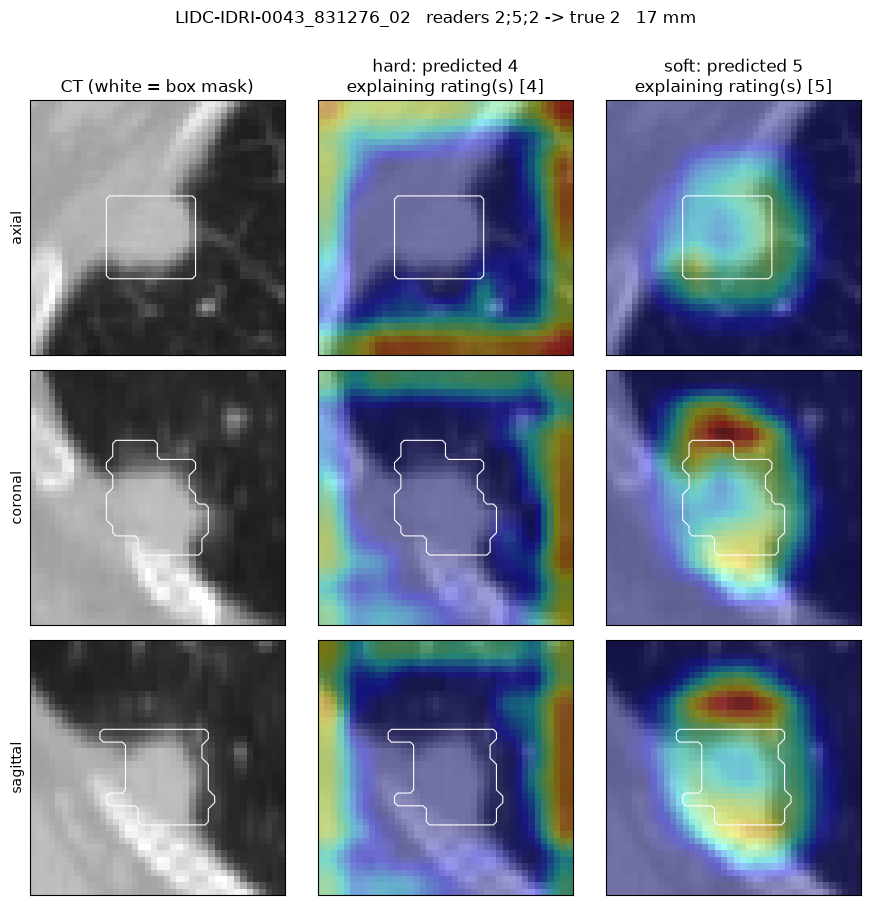

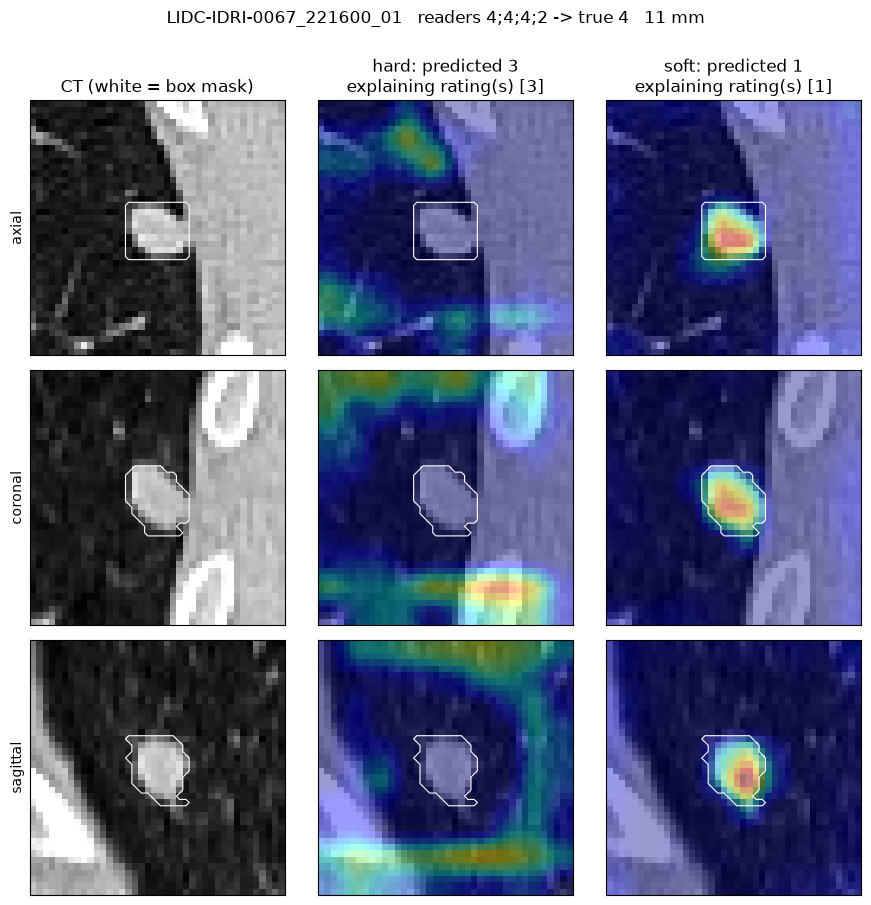

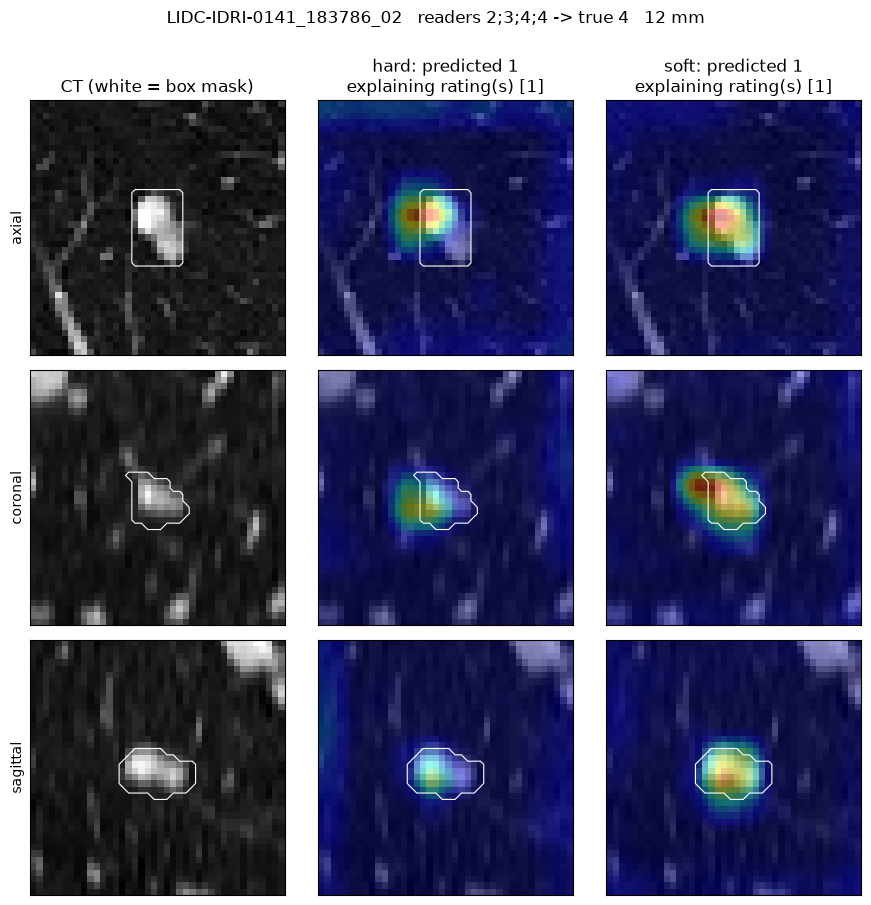

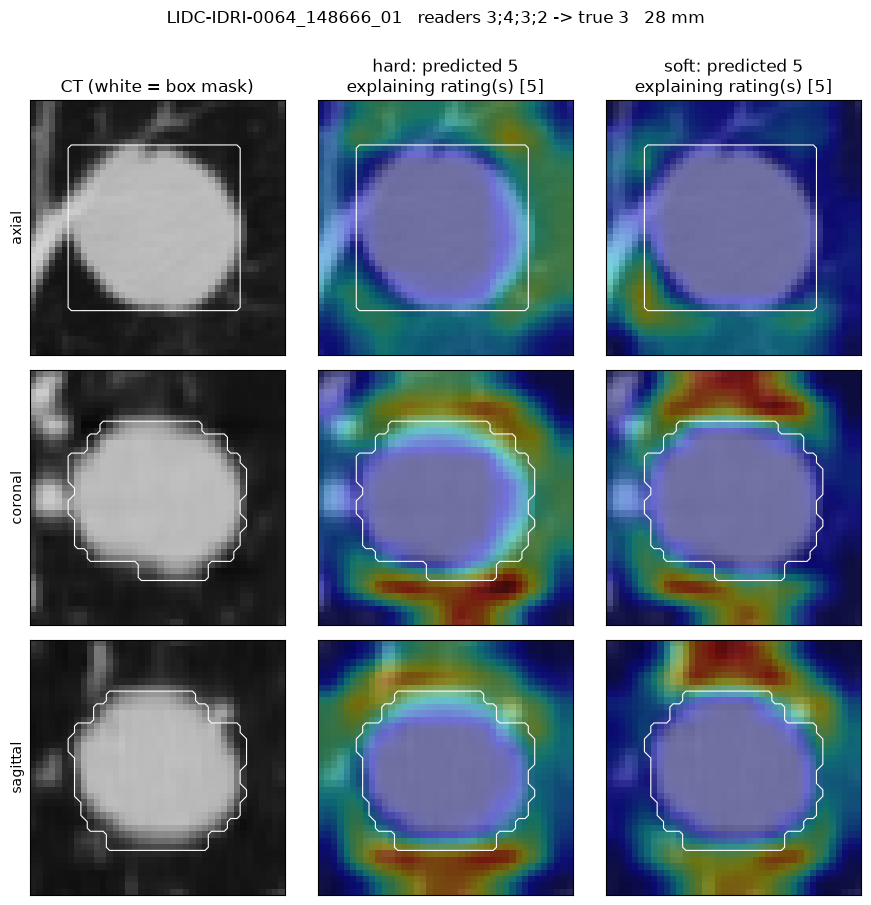

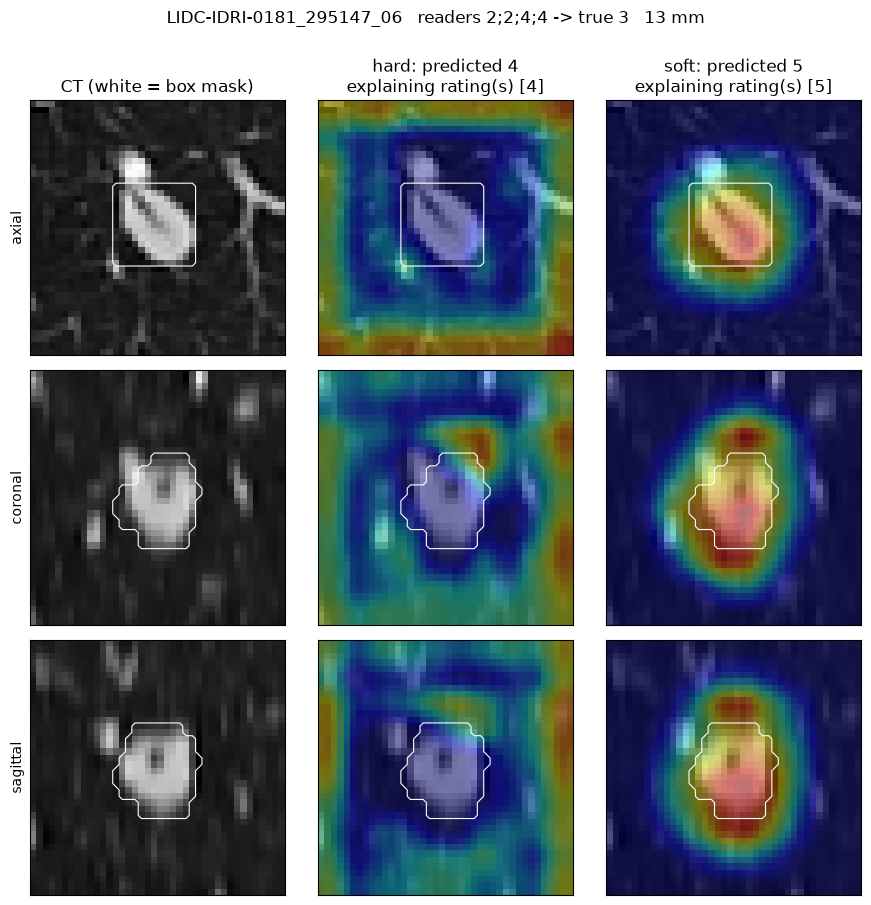

In [7]:
for i in worst.index[:5]:
    show(i)

## 6. For comparison: nodules both models got right

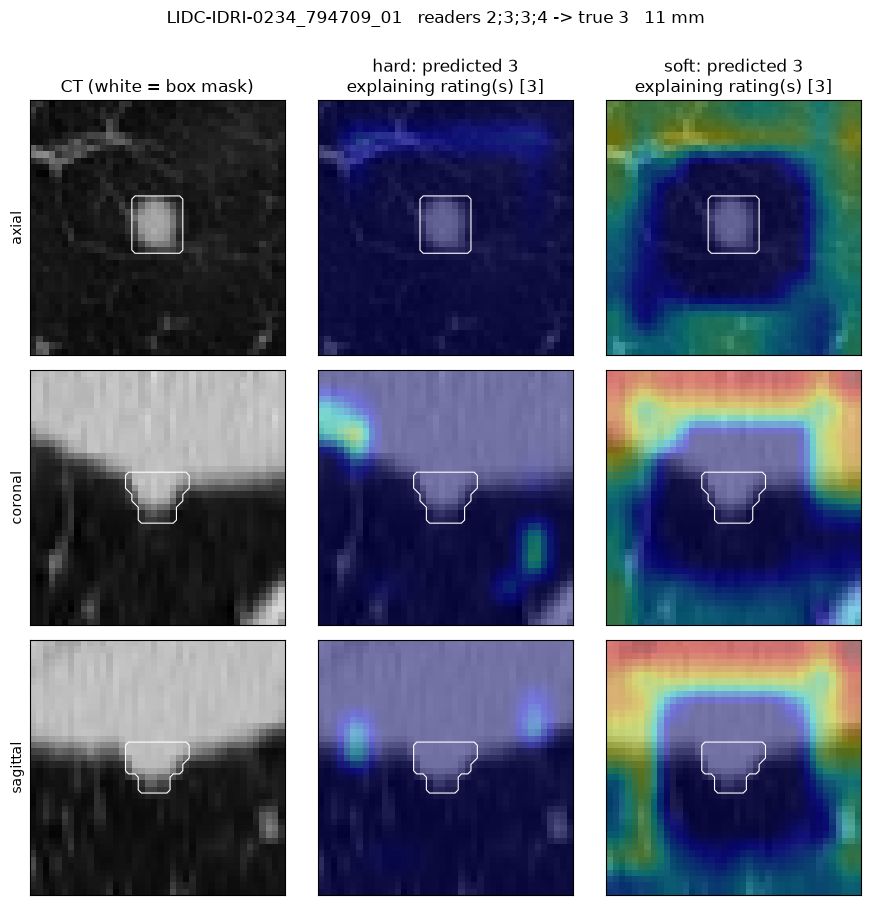

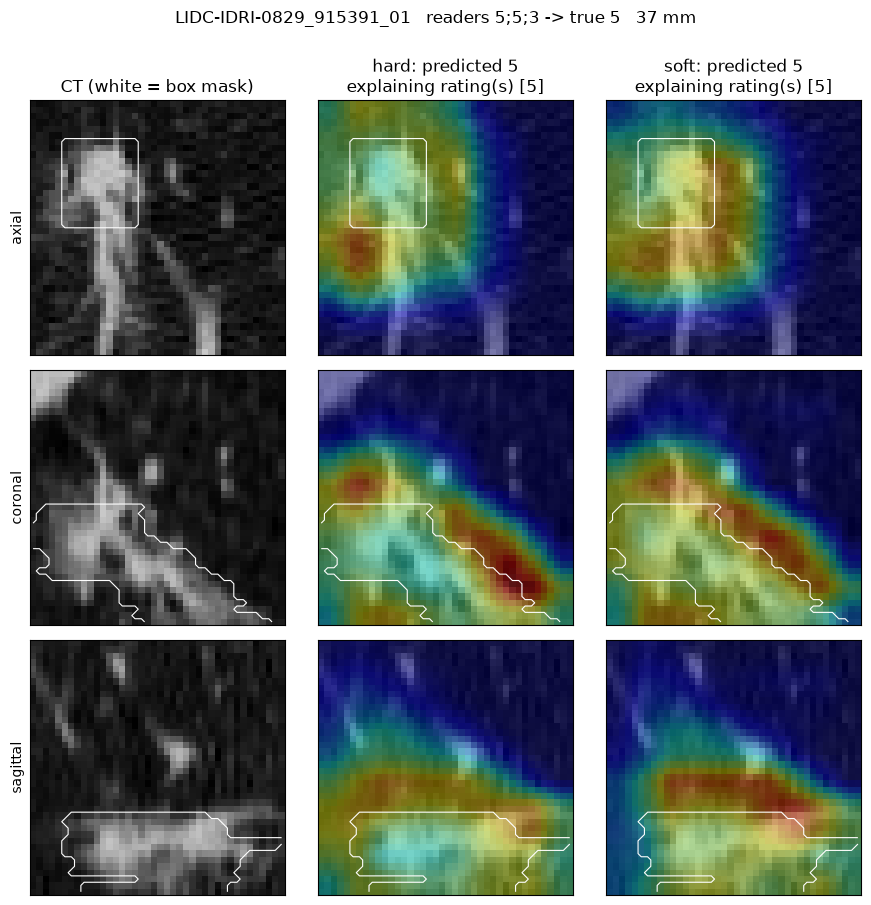

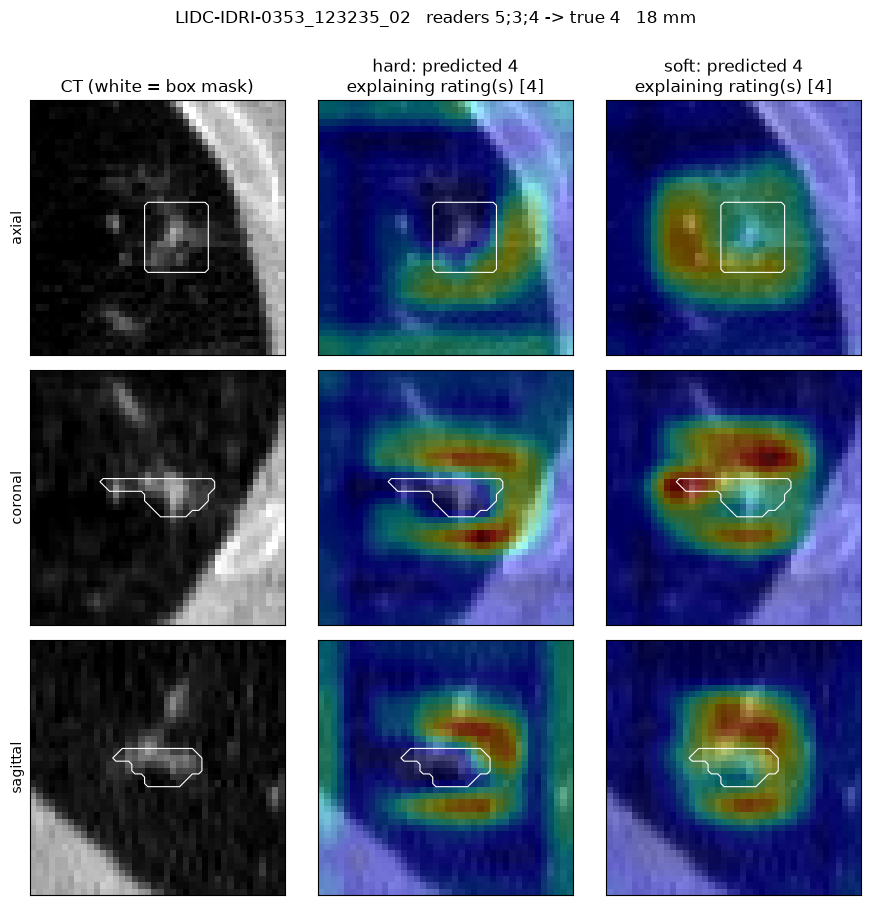

In [8]:
right = df[(df["err_hard"] == 0) & (df["err_soft"] == 0)]
for i in right.sample(3, random_state=0).index:
    show(i)

## 7. Hard vs soft where the readers disagreed most

`spread` = highest reader rating − lowest. Same question to both models: what looks suspicious?

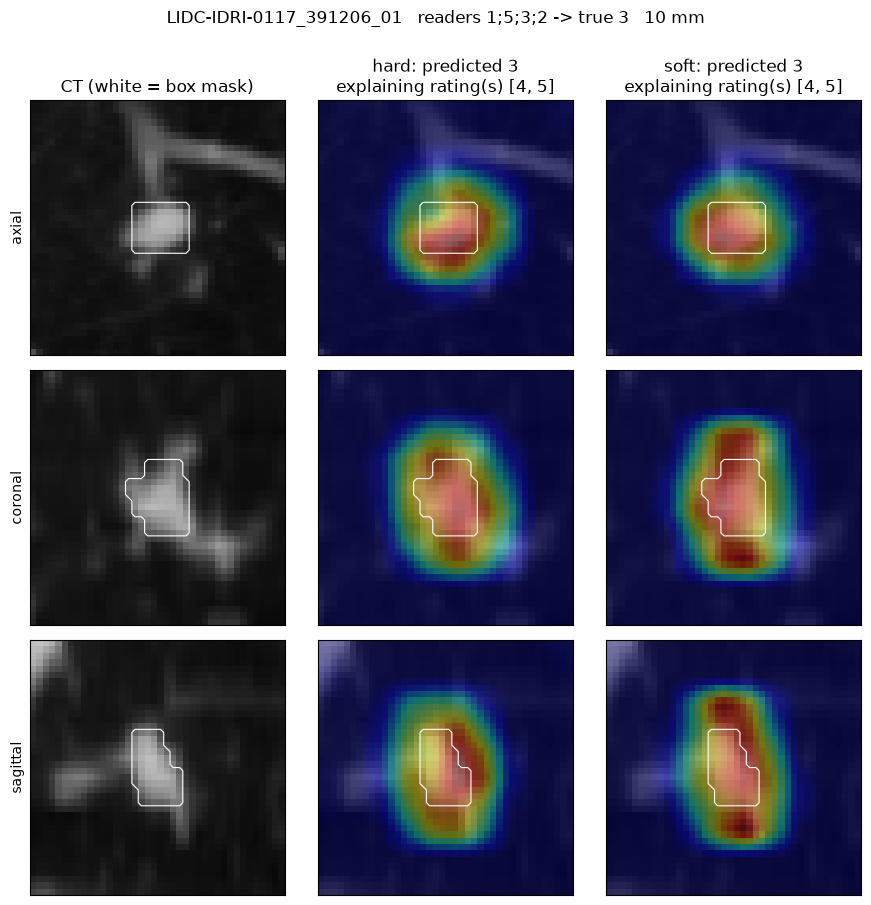

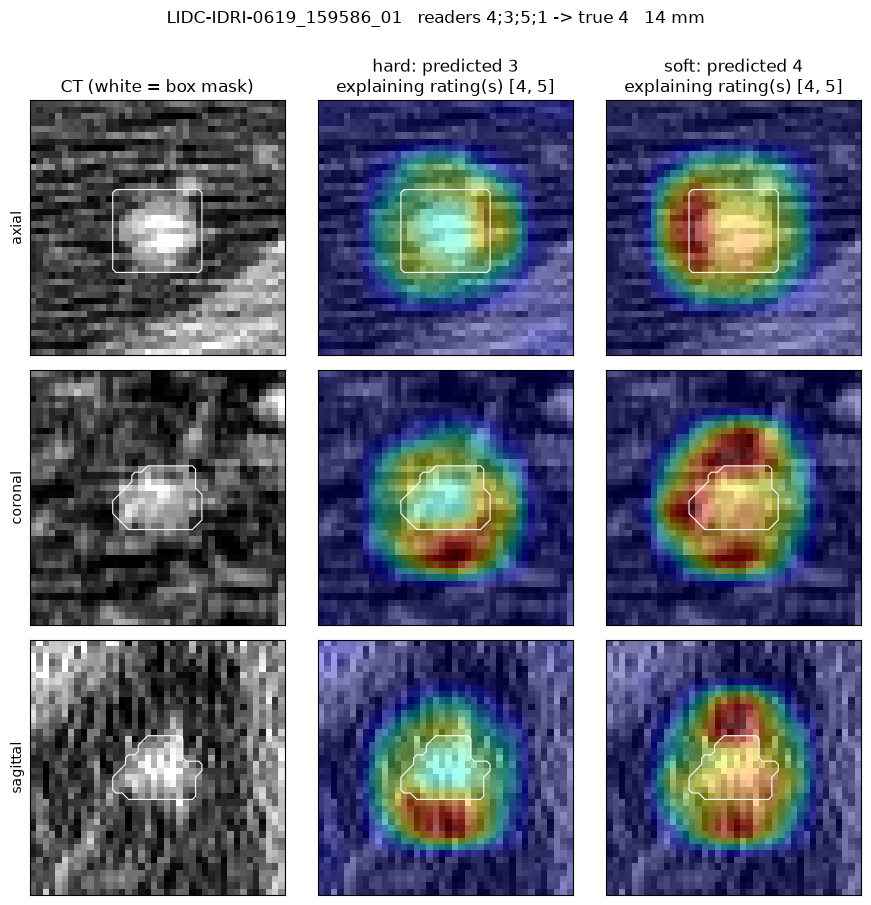

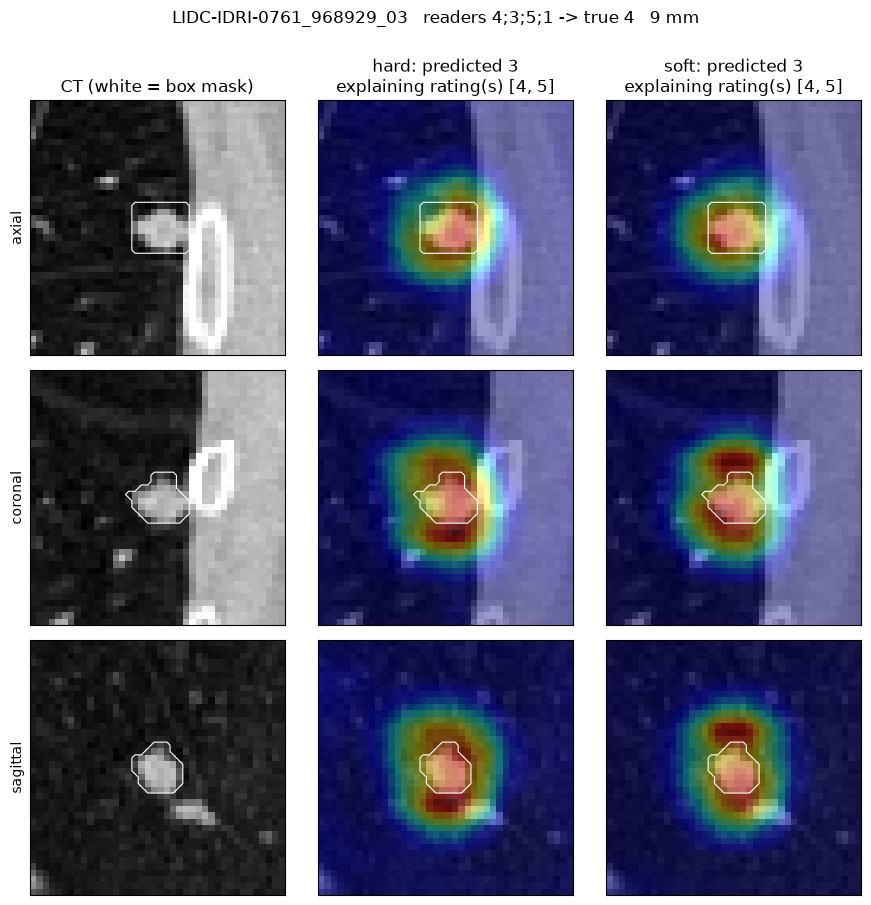

In [9]:
for i in df.sort_values("spread", ascending=False).index[:3]:
    show(i, classes=[4, 5])

## 8. The nodules that confused the CT-only models

The worst mistakes from grad_cam.ipynb, now with the mask runs. Compare each one with its figure there:

- `1002_740405_01` and `0181_295147_07`: the CT-only heat was on a neighbouring vessel. Is it on the nodule now?
- `0064_148666_01`: a 28 mm nodule rated 3 that the CT-only models called 5 (the "big → 5" habit). Does the mask make that worse?
- `0141_183786_02`: heat on the nodule, but rated 1 instead of 4.
- `0318_626096_01`: next to the chest wall; the CT-only hard model got it wrong, the soft one right.

                          ratings  hard  pred_hard  pred_soft  diameter_mm
nodule_key                                                                
LIDC-IDRI-1002_740405_01  5;4;3;3     4          3          3     9.045410
LIDC-IDRI-0181_295147_07      2;2     2          4          3    11.328125
LIDC-IDRI-0064_148666_01  3;4;3;2     3          5          5    27.734375
LIDC-IDRI-0141_183786_02  2;3;4;4     4          1          1    11.837891
LIDC-IDRI-0318_626096_01    1;1;3     1          3          3     8.658854


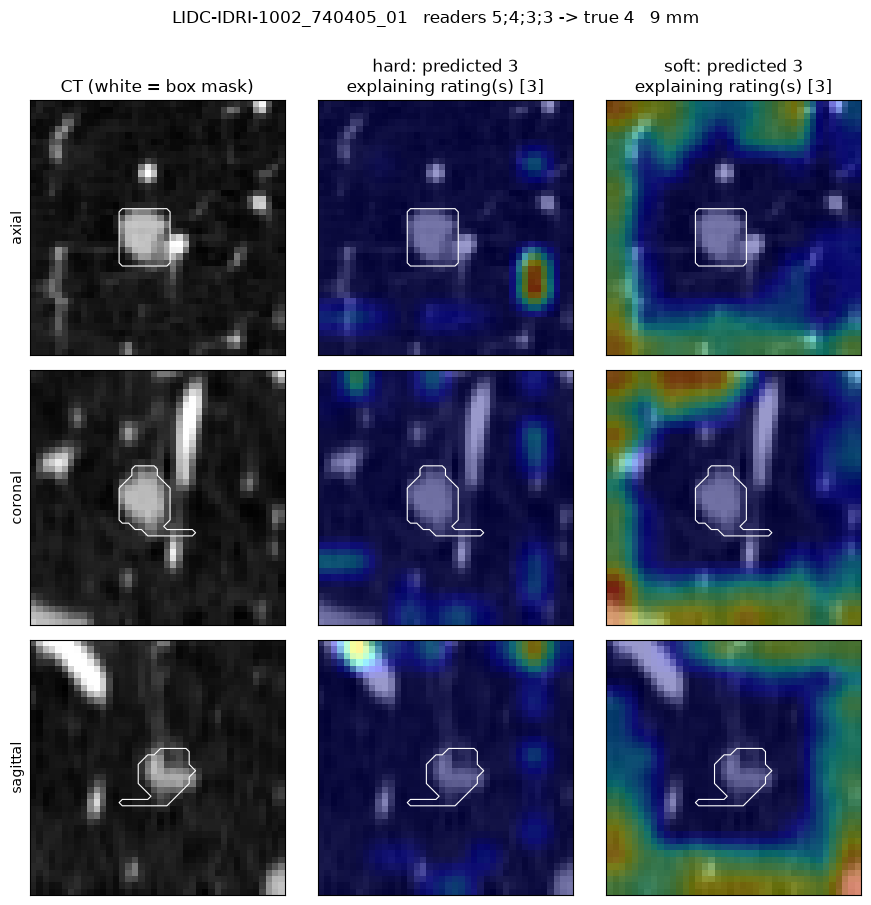

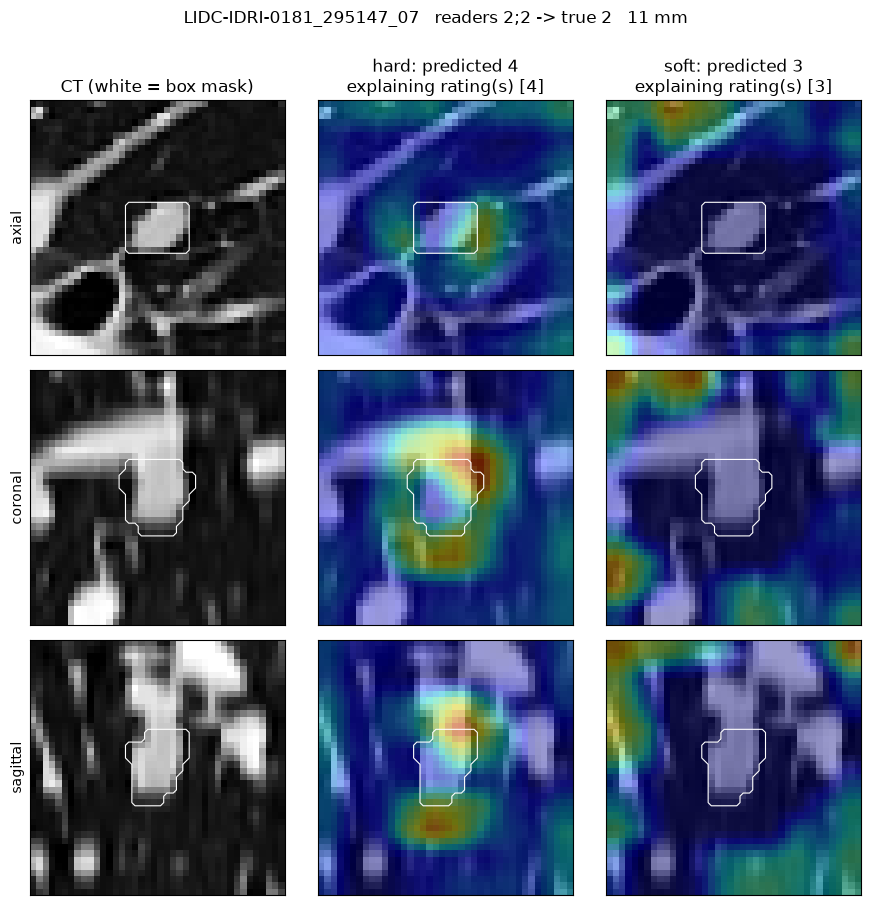

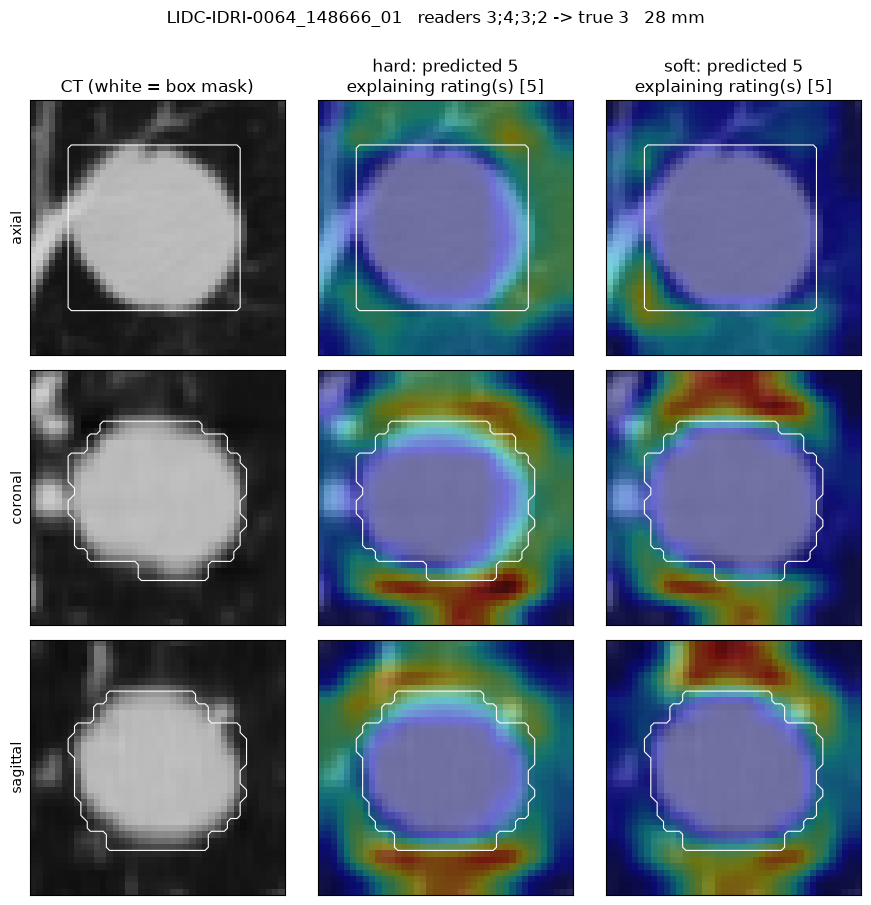

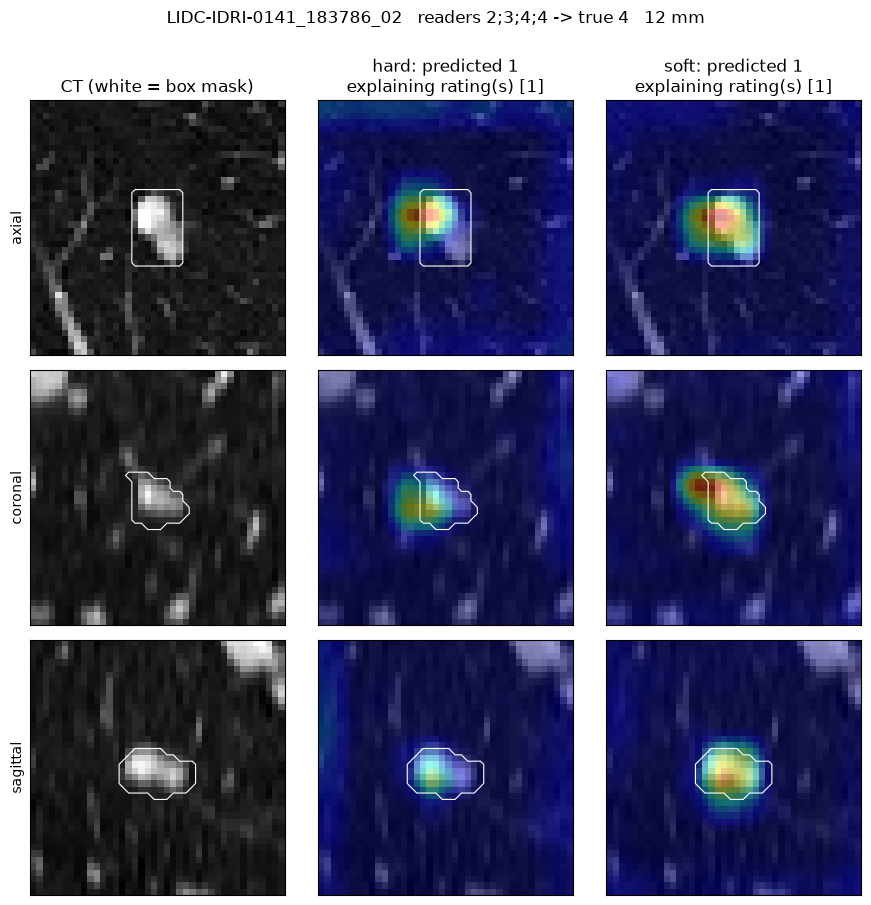

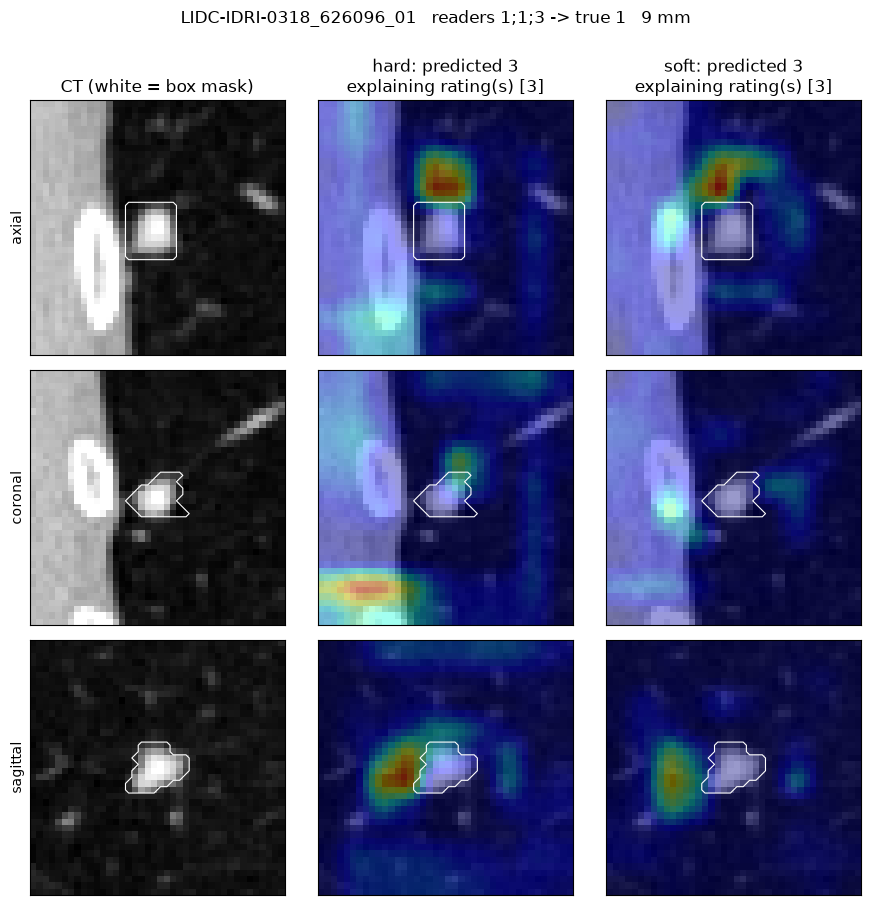

In [10]:
KEYS = ["LIDC-IDRI-1002_740405_01", "LIDC-IDRI-0181_295147_07", "LIDC-IDRI-0064_148666_01",
        "LIDC-IDRI-0141_183786_02", "LIDC-IDRI-0318_626096_01"]
print(df.set_index("nodule_key").loc[KEYS, ["ratings", "hard", "pred_hard", "pred_soft", "diameter_mm"]])
for key in KEYS:
    show_key(key)